# CSE 5104 - FL26 Project 1: Concrete Compressive Strength Analysis

**Group Members:** Lauren Lal, Emily Iorio, Katherine Feng  

In [6]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

### Part 1: Programming & Algorithm Implementation

In [7]:
## Import Data
df = pd.read_excel('data/Concrete_Data.xls', engine='xlrd')

df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


#### Gradient Descent from Scratch  
Implement a gradient descent optimization algorithm using MSE as the objective function.  

Codebase must support both univariate models (y=mx+b) and multivariate models (input x, vector of length p, p+1 parameters). 

Evaluate all models using both MSE and variance explained R^2 = 1 - MSE / Variance(observed)

In [8]:
from gradient_descent import gradient_descent, evaluate

#### Data Analysis  

Use the implemented algorithm, a third-part linear model optimization tool, and a third-party statistical tool for the following.

In [9]:
#seperate testing and training
testing = df.iloc[500:630]
training = pd.concat([df.iloc[:500], df.iloc[630:1030]])

print(df.columns)
print(len(training))
print(len(testing))

target = "Concrete compressive strength(MPa, megapascals) "

X_train = training.drop(columns=[target])
y_train = training[target]

X_test = testing.drop(columns=[target])
y_test = testing[target]

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')
900
130


In [10]:
X_train = X_train.to_numpy(dtype=float)
y_train = y_train.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)
y_test = y_test.to_numpy(dtype=float)

**Untransformed Features**

In [11]:
learning_rates= [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

for lr in learning_rates:
    weights, bias, loss = gradient_descent(X_train, y_train, learning_rate=lr, tolerance=1e-6)
    print(f"Learning Rate: {lr}")
    mse, r2 = evaluate(X_test, y_test, weights, bias)
    print(f"MSE: {mse}, R2: {r2}")

Learning Rate: 1e-08
MSE: 224.6401600702936, R2: -0.0038937200947559703
Learning Rate: 1e-07
MSE: 141.7513929888169, R2: 0.36652763605747063
Error: Non-finite loss value encountered.
Learning Rate: 1e-06
MSE: 6.725831831721794e+305, R2: -3.00570491766303e+303
Error: Non-finite loss value encountered.
Learning Rate: 1e-05
MSE: inf, R2: -inf
Error: Non-finite loss value encountered.
Learning Rate: 0.0001
MSE: 6.647200720847729e+305, R2: -2.9705654847202085e+303
Error: Non-finite loss value encountered.
Learning Rate: 0.001
MSE: inf, R2: -inf
Error: Non-finite loss value encountered.
Learning Rate: 0.01
MSE: inf, R2: -inf


/Users/katherine/Desktop/data mining/cse5104-project1/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/Users/katherine/Desktop/data mining/cse5104-project1/gradient_descent.py:19: RuntimeWarning: overflow encountered in square
  mse = np.mean(errors ** 2)
/Users/katherine/Desktop/data mining/cse5104-project1/gradient_descent.py:46: RuntimeWarning: overflow encountered in square
  mse = np.mean((y-y_pred) ** 2)


We will choose learning rate $\alpha = $ 1e-07

In [12]:
weights_unscaled, bias_unscaled, loss_unscaled = gradient_descent(
    X_train,
    y_train,
    learning_rate=1e-7,
    tolerance=1e-6
)
print(f"MSE: {mse}, R2: {r2}")

MSE: inf, R2: -inf


**Standarized/Normalized Features**

In [13]:
#Standardize the features
training_mean = X_train.mean(axis=0)
training_std = X_train.std(axis=0)

X_train_std = (X_train - training_mean) / training_std
X_test_std = (X_test - training_mean) / training_std

In [14]:
learning_rates= [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

for lr in learning_rates:
    weights, bias, loss = gradient_descent(X_train_std, y_train, learning_rate=lr, tolerance=1e-6)
    print(f"Learning Rate: {lr}")
    mse, r2 = evaluate(X_test_std, y_test, weights, bias)
    print(f"MSE: {mse}, R2: {r2}")


Learning Rate: 1e-08
MSE: 1015.2115777870446, R2: -3.536875896050775
Learning Rate: 1e-07
MSE: 1011.3935862715739, R2: -3.5198136855156834
Learning Rate: 1e-06
MSE: 974.0367607471388, R2: -3.3528698828807455
Learning Rate: 1e-05
MSE: 672.0720785687311, R2: -2.0034208438734074
Learning Rate: 0.0001
MSE: 104.16247912669178, R2: 0.5345086175505488
Learning Rate: 0.001
MSE: 133.3949577842348, R2: 0.40387168362952386
Learning Rate: 0.01
MSE: 141.08573604288478, R2: 0.3695023883348443


We will choose learning rate $\alpha = 0.0001$

In [15]:
weights_scaled, bias_scaled, loss_scaled = gradient_descent(
    X_train_std,
    y_train,
    learning_rate=0.0001,
    tolerance=1e-6
)
print(f"MSE: {mse}, R2: {r2}")

MSE: 141.08573604288478, R2: 0.3695023883348443


## TO-DO: Provide a figure showing loss over iterations for both

In [16]:
#Code here

## TO-DO: How does feature scaling affect convergence speed and stability? Explain why.

**answer here**

**Scaling & The Optimal Solution**  
Use the external linear model optimization tool to find the optimal solution for an untransformed multivariate model and a scaled multivariate model.  

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

**Untransformed Multivariate Model**

In [18]:
model = LinearRegression()
model.fit(X_train, y_train)

#get predictions 
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

#evaluate model 
train_mse = np.mean((y_train - y_train_pred) ** 2)
train_r2 = 1 - train_mse / np.var(y_train)
test_mse = np.mean((y_test - y_test_pred) ** 2)
test_r2 = 1 - test_mse / np.var(y_test)

print(f"Train MSE: {train_mse}, Train R2: {train_r2}")
print(f"Test MSE: {test_mse}, Test R2: {test_r2}")

Train MSE: 104.14373897310757, Train R2: 0.6240495572262079
Test MSE: 141.31386470838999, Test R2: 0.36848290484354596


**Scaled Multivariate Model**

In [19]:
#scale the data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [20]:
#fit the model
scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

y_train_scaled_pred = scaled_model.predict(X_train_scaled)
y_test_scaled_pred = scaled_model.predict(X_test_scaled)

In [21]:
train_mse_scaled = np.mean((y_train - y_train_scaled_pred) ** 2)
train_r2_scaled = 1 - train_mse_scaled / np.var(y_train)

test_mse_scaled = np.mean((y_test - y_test_scaled_pred) ** 2)
test_r2_scaled = 1 - test_mse_scaled / np.var(y_test)

print(f"Train MSE (Scaled): {train_mse_scaled}, Train R2 (Scaled): {train_r2_scaled}")
print(f"Test MSE (Scaled): {test_mse_scaled}, Test R2 (Scaled): {test_r2_scaled}")

Train MSE (Scaled): 104.14373897310753, Train R2 (Scaled): 0.6240495572262081
Test MSE (Scaled): 141.31386470839004, Test R2 (Scaled): 0.36848290484354573


## TODO Does a linear transformation meaningfully change the optimal mathematical solution?

**Non-Linear Transformations:**  

Apply a logarithmic transformation, log(𝑥 + 1), to your features and use your gradient descent implementation to train a new multivariate model. 

In [22]:
#transform via log 
X_train_log = np.log(X_train + 1)
X_test_log = np.log(X_test + 1)

print(X_train_log)

[[6.29341928 0.         0.         ... 6.94793707 6.51767127 3.36729583]
 [6.29341928 0.         0.         ... 6.96224346 6.51767127 3.36729583]
 [5.80964287 4.96633504 0.         ... 6.8384052  6.38856141 5.60211882]
 ...
 [5.00729639 4.94449549 4.69683737 ... 6.79503441 6.66057515 3.36729583]
 [5.07579862 5.23484494 0.         ... 6.89831082 6.67190636 3.36729583]
 [5.56796275 4.6200588  4.37323813 ... 6.76330737 6.63660251 3.36729583]]


In [23]:
#run with gradient descent
learning_rates= [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]

for lr in learning_rates:
    weights, bias, loss = gradient_descent(X_train_log, y_train, learning_rate=lr, tolerance=1e-6)
    print(f"Learning Rate: {lr}")
    mse, r2 = evaluate(X_test_log, y_test, weights, bias)
    print(f"MSE: {mse}, R2: {r2}")

Learning Rate: 1e-08
MSE: 945.8685828761779, R2: -3.2269891994699025
Learning Rate: 1e-07
MSE: 517.8736422296289, R2: -1.3143239262037594
Learning Rate: 1e-06
MSE: 234.36315210340902, R2: -0.04734476927279063
Learning Rate: 1e-05
MSE: 238.68644888351713, R2: -0.06666513695013876
Learning Rate: 0.0001
MSE: 131.4382450817054, R2: 0.41261603100482946
Learning Rate: 0.001
MSE: 55.57164691236993, R2: 0.7516560381136022
Error: Non-finite loss value encountered.
Learning Rate: 0.01
MSE: 1.1712362155263202e+306, R2: -5.2341339195382284e+303


/Users/katherine/Desktop/data mining/cse5104-project1/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


We will choose learning rate $\alpha = 0.001$

In [24]:
weights_log, bias_log, loss_log = gradient_descent(X_train_log, y_train, learning_rate=0.001, tolerance=1e-6)
log_mse, log_r2 = evaluate(X_test_log, y_test, weights_log, bias_log)
print(f"Log MSE: {log_mse}, Log R2: {log_r2}")

Log MSE: 55.57164691236993, Log R2: 0.7516560381136022


## TODO: Provide an updated figure showing loss over iterations. 

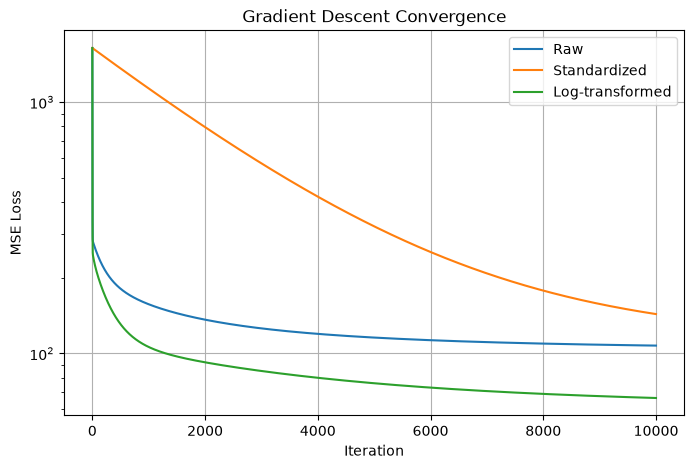

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(loss_unscaled, label="Raw")
plt.plot(loss_scaled, label="Standardized")
plt.plot(loss_log, label="Log-transformed")

plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Gradient Descent Convergence")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

## TODO: How does this non-linear feature transformation affect convergence speed and stability?

#answer here

Use an external linear model optimization tool to find the optimum solution for a
logarithmically transformed multivariate model.

In [26]:
log_model = LinearRegression()
log_model.fit(X_train_log, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[23.62, 2.3 , 0.2 ,..., 4.19,-6.65, 9.03]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,81
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[82.18,64.43,32.91,..., 3.25, 2.75, 1.12]"


In [27]:
y_train_log = log_model.predict(X_train_log)
y_test_log = log_model.predict(X_test_log)

In [28]:
train_log_mse = np.mean((y_train - y_train_log) ** 2)
train_log_r2 = 1 - train_log_mse / np.var(y_train)

test_log_mse = np.mean((y_test - y_test_log) ** 2)
test_log_r2 = 1 - test_log_mse / np.var(y_test)

print(f"Train Log MSE: {train_log_mse}, Train Log R2: {train_log_r2}")
print(f"Test Log MSE: {test_log_mse}, Test Log R2: {test_log_r2}")

Train Log MSE: 55.83241823500241, Train Log R2: 0.798449502931704
Test Log MSE: 54.38490724351376, Test Log R2: 0.7569594553680202


## TODO Construct a summary table comparing Training MSE, Testing MSE, Training R^2, and Testing R^2 across the 3 optimal models: Untransformed, Standardized/Normalized, and Log-Transformed.

In [ ]:
summary_table = pd.DataFrame({
    "Model": [
        "Untransformed",
        "Standardized/Normalized",
        "Log-Transformed"
    ],
    "Training MSE": [
        train_mse,
        train_mse_scaled,
        train_log_mse
    ],
    "Testing MSE": [
        test_mse,
        test_mse_scaled,
        test_log_mse
    ],
    "Training R^2": [
        train_r2,
        train_r2_scaled,
        train_log_r2
    ],
    "Testing R^2": [
        test_r2,
        test_r2_scaled,
        test_log_r2
    ]
})

summary_table.round(3)

,Model,Training MSE,Testing MSE,Training R^2,Testing R^2
0,Untransformed,104.143739,141.313865,0.62405,0.368483
1,Standardized/Normalized,104.143739,141.313865,0.62405,0.368483
2,Log-Transformed,55.832418,54.384907,0.79845,0.756959


## TODO How does a non-linear transformation differ from a linear transformation in its impact on the optimal model solution and overall predictive performance? Explain why.

#answer here

**Univariate vs Multivariate Coefficients:**  

## TO DO use gradient descent implementation to train 8 separate univariate models for each untransformed predictor until we achieve a positive R^2. 

In [30]:
##get each of the 8 feature names
feature_names = training.drop(columns=[target]).columns.tolist()
print(feature_names)

['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)']


In [31]:
##code here

## TO DO Which models were easy to train? Which models were hard?

#answerhere

## TODO Use an external linear model optimization tool to find the optimal solution for each of the univariate models.  Compare the individual coefficients from these univariate models to the corresponding feature weights found in the optimal untransformed multivariate model

In [32]:
##codehere

## TODO Are they identical? Support your answer with a table of coefficients. 

In [33]:
##code here

## TODO Why are univariate coefficients not equal to multivariate coefficients? Explain the roles of feature correlations and omitted variable bias.

#answerhere

**Statistical Significance (p-values):**  

Use a statistical analysis package (e.g., statsmodels.api.OLS) to extract feature 𝑝 -values.

## TO DO Present a consolidated table listing all features across three configurations:
- Untransformed Multivariate Model 𝑝 -values
- Standardized/Normalized Multivariate Model 𝑝 -values
- Log-Transformed Multivariate Model 𝑝 -values 

In [34]:
##codehere

# TODO Are there any trends between which predictors are important, and which univariate models were easy or hard to train?

In [35]:
#code here

#answerhere

## TODO Which transformation type drastically changes the statistical significance of the predictors, and which does not? Explain why.

#answerhere